# Red neuronal MLP sin escalado

Se reservan los últimos 24 meses para prueba. Los modelos se ajustan solamente con entrenamiento. La caché registra configuraciones y reutiliza resultados si no cambian los datos, parámetros o dependencias.

In [1]:
%matplotlib inline
import nbimporter
import functions
from pathlib import Path
from forecast_cache import fit_predict_cached, memory

Path("../submission").mkdir(parents=True, exist_ok=True)
df_orig = functions.load_data()
df_orig.head()

,yt_true
date,
1946-01-01,890
1946-02-01,992
1946-03-01,979
1946-04-01,959
1946-05-01,1110


In [2]:
# Los rezagos usan únicamente observaciones anteriores.
config = {"lags": 12, "hidden": 8, "random_state": 123456, "test_months": 24}
x_columns = [f"lagged_{i}m" for i in range(1, config["lags"] + 1)]
df_orig = functions.make_lagged_ts(
    df_orig, p_max=config["lags"], y_column="yt_true", fmt="lagged_{}m"
)
df_dropna = df_orig.dropna(subset=["yt_true"] + x_columns).copy()
df_dropna.head()

,yt_true,lagged_1m,lagged_2m,lagged_3m,lagged_4m,lagged_5m,lagged_6m,lagged_7m,lagged_8m,lagged_9m,lagged_10m,lagged_11m,lagged_12m
date,,,,,,,,,,,,,
1947-01-01,1488,1287.0,1301.0,1436.0,2092.0,3401.0,1539.0,1546.0,1110.0,959.0,979.0,992.0,890.0
1947-02-01,1517,1488.0,1287.0,1301.0,1436.0,2092.0,3401.0,1539.0,1546.0,1110.0,959.0,979.0,992.0
1947-03-01,1707,1517.0,1488.0,1287.0,1301.0,1436.0,2092.0,3401.0,1539.0,1546.0,1110.0,959.0,979.0
1947-04-01,1729,1707.0,1517.0,1488.0,1287.0,1301.0,1436.0,2092.0,3401.0,1539.0,1546.0,1110.0,959.0
1947-05-01,1788,1729.0,1707.0,1517.0,1488.0,1287.0,1301.0,1436.0,2092.0,3401.0,1539.0,1546.0,1110.0


Los pronósticos con rezagos se evalúan a un paso: cada mes usa los valores reales anteriores disponibles. No son una proyección recursiva de 24 meses desde un único origen.

In [3]:
# Partición cronológica; sin mezclar el futuro con entrenamiento.
(X_complete, y_complete, X_train, y_train, X_test, y_test) = functions.train_test_split(
    df=df_dropna, x_columns=x_columns, y_column="yt_true"
)
print(f"Entrenamiento: {len(X_train)} meses; prueba: {len(X_test)} meses")

Entrenamiento: 216 meses; prueba: 24 meses


In [4]:
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.compose import TransformedTargetRegressor

model = MLPRegressor(
    hidden_layer_sizes=(config["hidden"],),
    activation="logistic",
    learning_rate="adaptive",
    momentum=0.01,
    learning_rate_init=0.2,
    max_iter=10000,
    random_state=config["random_state"],
)
pipeline = model

In [5]:
# Primera ejecución: entrenar y cachear; siguientes: reutilizar si no hay cambios.
prediction_column = f"yt_pred_mlp_{config['hidden']}"
pipeline, predictions = fit_predict_cached(
    pipeline, X_train, y_train, X_complete, config
)
df_orig.loc[X_complete.index, prediction_column] = predictions
df_orig[["yt_true", prediction_column]].tail()

,yt_true,yt_pred_mlp_8
date,,
1966-08-01,6905,2810.313922
1966-09-01,5504,2810.313922
1966-10-01,5457,2810.313922
1966-11-01,5198,2810.313922
1966-12-01,4890,2810.313922


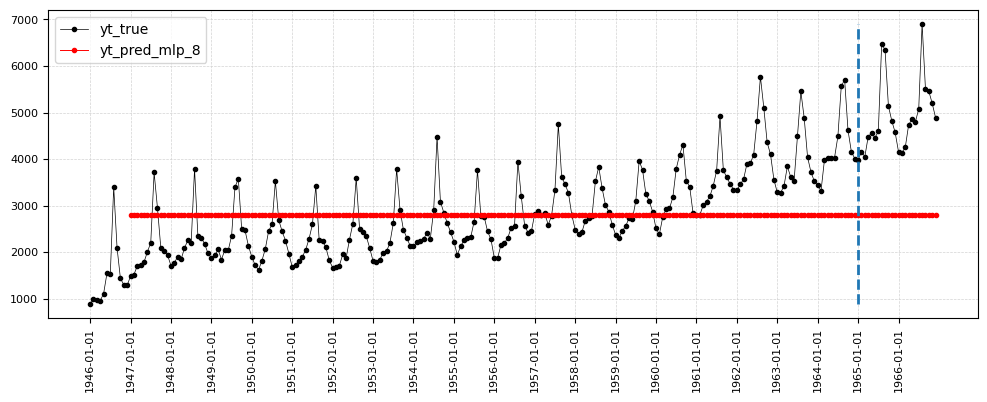

In [6]:
# Gráfica de los pronósticos
functions.plot_time_series(df=df_orig, yt_col="yt_true")

In [7]:
# Métricas sobre las filas con pronóstico; se conservan los últimos 24 meses de prueba.
evaluation = df_orig[["yt_true", prediction_column]].dropna()
metrics = memory.cache(functions.compute_evaluation_metrics)(evaluation)
metrics

,Metrics,yt_pred_mlp_8
0,MSE Train,793456.14
1,MSE Test,4949339.42
2,MAE Train,718.88
3,MAE Test,2091.06


In [8]:
# Agregar resultados sin eliminar las columnas de los otros modelos.
functions.save_forecasts(df_orig)
functions.save_metrics(metrics)